# Modelo XGBoost para pronosticar un mes, hora por hora

Desde un día de corte t se pronostican las 24 horas de cada uno de los 30 días
siguientes. Son 30 modelos directos, uno por horizonte: el mismo modelo en un
ciclo, con el objetivo de ese día. Las columnas son las de la selección congelada
(`2d_seleccion_variables.py`).

| Etapa | Qué hace | Datos |
|---|---|---|
| 0 | Arma objetivos y calendario para h = 1 a 30 | todo el panel |
| 1 | Comprueba el flujo y mide el tiempo | hasta 2022 |
| 2 | Búsqueda de hiperparámetros con pliegues anuales | hasta 2022 |
| 3 | Walk-forward mensual con las 3 mejores combinaciones | hasta 2022 |
| 4 | Variantes: pseudo-Huber, 3 años, corrección de sesgo, reentrenar por semana | hasta 2022 |
| 5 | Congela la configuración | |
| 6 | Test, una sola vez | 2023-2025 |
| 6b | Test en 2026, con la misma configuración | 2026, hasta el 6 de octubre |
| 7 | Mes final: del 7 de octubre al 5 de noviembre de 2026 | hasta el 6 de octubre de 2026 |

Cada etapa guarda en `resultados/modelo_xgboost/` y no se repite si el archivo ya
existe. La etapa 6 solo corre con la variable de entorno `CORRER_TEST=1`, la 6b con
`CORRER_2026=1` y la 7 con `CORRER_FINAL=1`.

**Cómo leer los resultados.** La medida es el test (2023-2025). El mes final es una
demostración con un solo mes. Los errores de 2020-2022 son optimistas, porque esa
ventana se usó para la selección y para este ajuste. Y 2023-2026 no está intacto:
los experimentos de `legacy/experimentos_xgboost/` ya evaluaron ahí con la selección lineal.
Nada de eso se usa aquí para decidir.

**Resultado.** Con el criterio de la etapa 6, el modelo funciona en los cuatro bloques
de 2023-2025. En 2026 solo funciona hasta h = 7: de h = 8 a 14 la mejora no se distingue
de la suerte, y de h = 15 a 30 pierde contra el ingenuo semanal. El detalle está en
`resultados/modelo_xgboost/RESULTADOS.md`.

In [1]:
import json
import os
import shutil
import time
import warnings
from datetime import date, datetime
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from joblib import Parallel, delayed
from scipy import stats

# pandas 2.3 con numpy 2.5 avisa en cada pd.Timedelta(days=...) por una unidad
# que usa por dentro; no afecta el resultado
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

PANELES = Path("paneles") if Path("paneles").exists() else Path(".")
SALIDA = Path("resultados/modelo_xgboost")
SALIDA.mkdir(parents=True, exist_ok=True)

HORIZONTES = list(range(1, 31))
ANCLAS = [1, 2, 3, 4, 5, 6, 7, 14, 30]
AÑOS_VALIDACION = [2020, 2021, 2022]
MESES_VALIDACION = ("2020-01-01", "2022-12-01")
SEMANAS_DE_PRUEBA = ("2022-01-01", "2022-12-31")
FIN_VALIDACION = np.datetime64("2022-12-31")
MESES_TEST = ("2023-01-01", "2025-12-01")
FIN_TEST = np.datetime64("2025-12-31")
ORIGEN_FINAL = np.datetime64("2026-10-06")
FIN_MES_FINAL = date(2026, 11, 5)
CORRER_TEST = os.environ.get("CORRER_TEST") == "1"
CORRER_2026 = os.environ.get("CORRER_2026") == "1"
CORRER_FINAL = os.environ.get("CORRER_FINAL") == "1"

N_COMBINACIONES = 30
MAX_ARBOLES = 1200
CADA_ARBOLES = 50
N_FINALISTAS = 3
HUBER_SLOPE = 0.2
VENTANA_CORTA = 1096                           # 3 años, en días
DIAS_SESGO = 30

# La fecha más lejana que puede tener un objetivo. Sube solo en las etapas 6 y 7.
TECHO = FIN_VALIDACION

# Con GPU entrena en ella. Fuente de los parámetros: ML Zoomcamp, 06-trees/08-xgb-tuning.md.
DISPOSITIVO = "cuda" if shutil.which("nvidia-smi") else "cpu"
# Un modelo a la vez con todos los hilos. Se midió repartirlos en este computador (10
# núcleos, 20 hilos): 5 modelos de 4 hilos y 10 de 2 van 1,5 veces más rápido, y además
# cambian un poco los resultados. No alcanzó el doble que se pidió para cambiarlo.
HILOS_POR_MODELO = -1
MODELOS_A_LA_VEZ = 1
COMUNES = dict(tree_method="hist", device=DISPOSITIVO, n_jobs=HILOS_POR_MODELO, random_state=0,
               learning_rate=0.03, eval_metric="rmse")

# Colores: paleta categórica de la guía de gráficas del proyecto, tema claro
AZUL, NARANJA = "#2a78d6", "#eb6834"
FONDO, TEXTO, TEXTO_2, REJILLA = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({"figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
                     "axes.edgecolor": REJILLA, "axes.labelcolor": TEXTO_2, "text.color": TEXTO,
                     "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "axes.grid": True,
                     "grid.color": REJILLA, "grid.linewidth": 1, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 2})


def en_paralelo(tareas):
    return Parallel(n_jobs=MODELOS_A_LA_VEZ, prefer="threads")(tareas)


def ancla(h):
    """El horizonte que le presta columnas e hiperparámetros a h."""
    return h if h <= 7 else 7 if h <= 10 else 14 if h <= 21 else 30


def guardar(df, ruta):
    """Escribe aparte y renombra, para que un archivo a medias nunca cuente como etapa hecha."""
    tmp = ruta.with_name(ruta.name + ".tmp")
    gz = "gzip" if ruta.suffix == ".gz" else None
    for intento in range(5):                       # OneDrive a veces bloquea el archivo un momento
        try:
            df.to_csv(tmp, index=False, compression=gz, float_format="%.7g")
            tmp.replace(ruta)
            return
        except OSError:
            time.sleep(5 * (intento + 1))
    raise OSError(f"no se pudo guardar {ruta}")

## Etapa 0. Datos

El panel solo trae objetivos y calendario para los 9 horizontes de la selección. Aquí
se arman para los 30 días. Las columnas van por bandas: los días 8-10 usan la lista
de h = 7, los días 11-21 la de h = 14 y los días 22-30 la de h = 30. El calendario
objetivo siempre es el del día t+h.

In [2]:
tabla = pd.read_csv(PANELES / "panel_horario_modelo.csv.gz", parse_dates=["fecha"])
seleccion = pd.read_csv(PANELES / "panel_horario_modelo_columnas.csv")
assert len(tabla) == tabla["fecha"].nunique() * 24, "los desplazamientos suponen días completos"

F = tabla["fecha"].to_numpy("datetime64[D]")
PRECIO = tabla["precio"].to_numpy(float)
LP = np.log(PRECIO)


def adelante(x, k):
    out = np.full(len(x), np.nan)
    out[:-k] = x[k:]
    return out


Y = {h: adelante(LP, 24 * h) - LP for h in HORIZONTES}

# El calendario del día objetivo, con la misma fórmula de 2c_caracteristicas_horarias.py
fechas = pd.DatetimeIndex(tabla["fecha"])
dias = pd.date_range(fechas.min(), fechas.max() + pd.offsets.Day(60))
co_festivos = holidays.Colombia(years=range(dias[0].year, dias[-1].year + 1))
es_festivo = pd.Series([int(d in co_festivos) for d in dias], index=dias)
nuevas = {}
for h in HORIZONTES:
    if h in ANCLAS:
        continue
    objetivo = fechas.shift(h, freq="D")
    angulo = 2 * np.pi * objetivo.dayofweek.to_numpy() / 7
    nuevas[f"dia_semana_h{h}"] = objetivo.dayofweek.to_numpy()
    nuevas[f"es_festivo_h{h}"] = es_festivo.reindex(objetivo).to_numpy()
    nuevas[f"dia_semana_h{h}_sin"] = np.sin(angulo)
    nuevas[f"dia_semana_h{h}_cos"] = np.cos(angulo)
tabla = pd.concat([tabla, pd.DataFrame(nuevas)], axis=1)

numericas = [c for c in tabla.columns if c not in ("fecha", "bloque", "precio") and not c.startswith("y_h")]
M = tabla[numericas].to_numpy(np.float32)
POS = {c: j for j, c in enumerate(numericas)}


def columnas(h):
    """Las columnas de la selección congelada para h, con el calendario de su día objetivo."""
    a = ancla(h)
    c = seleccion[seleccion[f"entra_h{a}"]].sort_values(f"orden_h{a}", na_position="first")["columna"]
    return [x.replace(f"_h{a}", f"_h{h}") if x.startswith(("dia_semana_h", "es_festivo_h")) else x
            for x in c]


print(f"{len(tabla):,} filas; {F.min()} a {F.max()}")
print("columnas por horizonte:", {h: len(columnas(h)) for h in (1, 2, 7, 8, 11, 14, 22, 30)})

101,712 filas; 2015-03-01 a 2026-10-06
columnas por horizonte: {1: 37, 2: 27, 7: 37, 8: 37, 11: 27, 14: 27, 22: 27, 30: 27}


## Reglas comunes

- **Purga.** Se entrena con las filas t ≤ corte − (h + 1), para que ningún objetivo del
  entrenamiento caiga en el periodo evaluado. Fuente: López de Prado (2018), capítulo 7.
- **El objetivo no cruza de ventana.** Una fila se evalúa solo si t + h cae dentro de su
  ventana. `datos()` falla si un objetivo pasa de `TECHO`, y por eso la búsqueda no
  puede leer 2023. El paso 2d no tenía esa protección: su `matriz()` vigilaba las
  columnas, pero no la respuesta (ver `docs/PANEL_HORARIO.md`).
- **El error.** Promedio por día del error cuadrático en log, con error estándar de
  Newey-West (h − 1 + 7 rezagos), porque los días seguidos se parecen y los objetivos
  se traslapan. Fuente: Newey y West (1987).

In [3]:
def para_entrenar(h, corte, ventana=None):
    m = (F <= corte - (h + 1)) & ~np.isnan(Y[h])
    return m if ventana is None else m & (F >= corte - ventana)


def para_medir(h, ini, fin, tope):
    return (F >= ini) & (F <= fin) & (F + h <= tope) & ~np.isnan(Y[h])


def datos(filas, h, cols):
    """Columnas y objetivo de una máscara de filas. Nunca lee un objetivo posterior a TECHO."""
    assert (F[filas] + h).max() <= TECHO, f"objetivo posterior a {TECHO}"
    i = np.flatnonzero(filas)
    return M[np.ix_(i, [POS[c] for c in cols])], Y[h][i]


def ajustar(filas, h, cols, p, medir=None):
    A, y = datos(filas, h, cols)
    m = xgb.XGBRegressor(**{**COMUNES, **p})
    if medir is None:
        return m.fit(A, y)
    B, z = datos(medir, h, cols)
    return m.fit(A, y, eval_set=[(B, z)], verbose=False)


def walk_forward(h, p, cortes, fin, tope, ventana=None):
    """Reentrena en cada corte y pronostica, desde cada día, hasta el corte siguiente."""
    cols = columnas(h)
    siguientes = list(cortes[1:]) + [fin + 1]

    def un_corte(ini, sig):
        ev = para_medir(h, ini, sig - 1, tope)
        if not ev.any():
            return None
        m = ajustar(para_entrenar(h, ini, ventana), h, cols, p)
        return np.flatnonzero(ev), m.predict(datos(ev, h, cols)[0])

    partes = en_paralelo(delayed(un_corte)(i, s) for i, s in zip(cortes, siguientes))
    partes = [x for x in partes if x is not None]
    return np.concatenate([x[0] for x in partes]), np.concatenate([x[1] for x in partes])


def por_dia(idx, pred, h):
    e = Y[h][idx] - pred
    d = pd.DataFrame({"fecha": F[idx], "e_dia": e, "mse_dia": e ** 2})
    return d.groupby("fecha", as_index=False).mean()


def media_y_error_estandar(d, L):
    """Promedio de una serie diaria y su error estándar de Newey-West con L rezagos."""
    u = d - d.mean()
    v = (u * u).mean()
    for l in range(1, min(L, len(d) - 1) + 1):
        v += 2 * (1 - l / (L + 1)) * (u[l:] * u[:-l]).mean()
    return d.mean(), np.sqrt(v / len(d))


def correccion_sesgo(e_dia, h):
    """
    El error medio de los últimos DIAS_SESGO días ya conocidos. Desde el día d solo se
    conocen las filas t ≤ d - h, porque el objetivo de t se ve en t + h.
    """
    c = pd.Series(e_dia).rolling(DIAS_SESGO, min_periods=10).mean().shift(h)
    return c.fillna(0).to_numpy()


def meses(ini, fin):
    return list(pd.date_range(ini, fin, freq="MS").to_numpy().astype("datetime64[D]"))

## Etapa 1. Comprobar el flujo

- El mismo modelo de la selección, con h = 7 y sus columnas, tiene que dar cerca de
  0,3077 de RMSE en 2020-2022. No da exacto porque aquí se dejan por fuera las filas
  cuyo objetivo cae en 2023 y porque el panel va redondeado a 6 cifras.
- Alterar objetivos posteriores al corte no puede cambiar el pronóstico.
- Pedir un objetivo de 2023 tiene que fallar.

In [4]:
inicio_val = np.datetime64("2020-01-01")
p_2d = dict(max_depth=5, learning_rate=0.05, n_estimators=600, min_child_weight=10,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0)
cols = columnas(7)
tr = para_entrenar(7, inicio_val)
ev = para_medir(7, inicio_val, FIN_VALIDACION, FIN_VALIDACION)
t0 = time.time()
modelo = ajustar(tr, 7, cols, p_2d)
segundos = time.time() - t0
A, y = datos(ev, 7, cols)
rmse_7 = float(np.sqrt(np.mean((y - modelo.predict(A)) ** 2)))
print(f"h = 7: RMSE {rmse_7:.4f} (selección: 0,3077); {segundos:.1f} s por entrenamiento con {tr.sum():,} filas")
assert abs(rmse_7 - 0.3077) < 0.01, "el flujo no reproduce la selección"

# Sin fuga: alterar todo objetivo que caiga desde el corte en adelante no cambia nada
corte = np.datetime64("2021-06-01")
p_corto = dict(max_depth=3, n_estimators=50, min_child_weight=10, subsample=1.0, colsample_bytree=1.0)
tr = para_entrenar(7, corte)
ev = para_medir(7, corte, corte + 29, FIN_VALIDACION)
assert (F[tr] + 7).max() < corte
antes = ajustar(tr, 7, cols, p_corto).predict(datos(ev, 7, cols)[0])
original = Y[7].copy()
try:
    Y[7][F + 7 >= corte] += 5.0
    despues = ajustar(tr, 7, cols, p_corto).predict(datos(ev, 7, cols)[0])
finally:
    Y[7] = original
assert np.array_equal(antes, despues), "hay fuga: el pronóstico cambió"
print("sin fuga: alterar objetivos posteriores al corte no cambia el pronóstico")

# La búsqueda no puede leer el test
try:
    datos(para_medir(1, np.datetime64("2023-01-01"), np.datetime64("2023-01-31"), np.datetime64("2023-12-31")), 1, ["lp"])
except AssertionError:
    print("protegido: pedir un objetivo de 2023 falla")
else:
    raise RuntimeError("la protección del test no funcionó")

h = 7: RMSE 0.2997 (selección: 0,3077); 2.1 s por entrenamiento con 42,240 filas


sin fuga: alterar objetivos posteriores al corte no cambia el pronóstico
protegido: pedir un objetivo de 2023 falla


## Etapa 2. Búsqueda de hiperparámetros

30 combinaciones al azar, las mismas para cada horizonte ancla, en tres pliegues
anuales: entrenar con todo lo anterior y medir en 2020, 2021 y 2022. Cada horizonte
fuera de las anclas usa después los hiperparámetros de su ancla.

`min_child_weight` se cuenta en horas: 240 obliga a que cada hoja tenga el equivalente
a 10 días. El número de árboles se lee de la curva de error de cada entrenamiento,
cada 50 árboles, sin volver a entrenar. Fuente de los parámetros: ML Zoomcamp,
`06-trees/08-xgb-tuning.md`.

In [5]:
rng = np.random.default_rng(0)
COMBINACIONES = [dict(max_depth=int(rng.integers(3, 9)),
                      min_child_weight=int(rng.choice([10, 50, 240])),
                      subsample=round(float(rng.uniform(0.7, 0.9)), 2),
                      colsample_bytree=round(float(rng.uniform(0.5, 0.9)), 2),
                      reg_lambda=round(float(10 ** rng.uniform(0, 1)), 2))
                 for _ in range(N_COMBINACIONES)]


def una_combinacion(a, i, p, cols):
    curvas = []
    for año in AÑOS_VALIDACION:
        ini, fin = np.datetime64(f"{año}-01-01"), np.datetime64(f"{año}-12-31")
        m = ajustar(para_entrenar(a, ini), a, cols, dict(p, n_estimators=MAX_ARBOLES),
                    para_medir(a, ini, fin, fin))
        curvas.append(np.array(m.evals_result()["validation_0"]["rmse"]) ** 2)
    curvas = np.array(curvas)
    marcas = np.arange(CADA_ARBOLES - 1, MAX_ARBOLES, CADA_ARBOLES)
    mejor = marcas[curvas[:, marcas].mean(axis=0).argmin()]
    return dict(combinacion=i, **p, n_estimators=int(mejor + 1),
                **{f"mse_{a_}": curvas[k, mejor] for k, a_ in enumerate(AÑOS_VALIDACION)},
                mse=curvas[:, mejor].mean())


def buscar(a):
    ruta = SALIDA / f"etapa2_h{a}.csv"
    if ruta.exists():
        return pd.read_csv(ruta)
    cols = columnas(a)
    filas = en_paralelo(delayed(una_combinacion)(a, i, p, cols) for i, p in enumerate(COMBINACIONES))
    r = pd.DataFrame(filas).sort_values("mse")
    guardar(r, ruta)
    return r


t0 = time.time()
busqueda = {a: buscar(a) for a in ANCLAS}
print(f"etapa 2: {(time.time() - t0) / 60:.0f} min")
pd.concat([b.head(1).assign(h=a) for a, b in busqueda.items()]).set_index("h").round(4)

etapa 2: 77 min


,combinacion,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,n_estimators,mse_2020,mse_2021,mse_2022,mse
h,,,,,,,,,,,
1,7,5,240,0.83,0.78,2.45,650,0.0178,0.0109,0.0183,0.0157
2,10,7,50,0.76,0.74,2.18,200,0.0302,0.0161,0.0322,0.0261
3,25,4,50,0.75,0.82,8.39,200,0.0384,0.0234,0.0505,0.0374
4,3,5,240,0.71,0.79,1.50,200,0.0463,0.0295,0.0627,0.0462
5,15,6,50,0.74,0.54,3.80,100,0.0556,0.0367,0.0740,0.0554
6,5,5,10,0.72,0.77,4.44,150,0.0717,0.0468,0.0846,0.0677
7,14,8,50,0.86,0.59,1.13,100,0.0727,0.0524,0.0937,0.0729
14,17,3,50,0.72,0.75,8.46,200,0.0878,0.0842,0.1343,0.1021
30,0,8,50,0.75,0.52,1.04,900,0.1604,0.1435,0.2314,0.1784


## Etapa 3. Walk-forward mensual

Las 3 mejores combinaciones de cada ancla, reentrenando el 1 de cada mes de 2020 a
2022 y pronosticando desde todos los días del mes. Queda la más simple de las que
estén a un error estándar de la mejor: menos profundidad y hojas más grandes. Fuente de
la regla: SLDA, clases 7 y 8; Hastie et al. (2009), sección 7.10.

In [6]:
ENTEROS = ["max_depth", "min_child_weight", "n_estimators"]
DECIMALES = ["subsample", "colsample_bytree", "reg_lambda"]


def a_parametros(fila):
    return {**{k: int(fila[k]) for k in ENTEROS}, **{k: float(fila[k]) for k in DECIMALES}}


def mensual(a):
    ruta = SALIDA / f"etapa3_h{a}.csv.gz"
    if ruta.exists():
        return pd.read_csv(ruta)
    partes = []
    for _, fila in busqueda[a].head(N_FINALISTAS).iterrows():
        idx, pred = walk_forward(a, a_parametros(fila), meses(*MESES_VALIDACION), FIN_VALIDACION, FIN_VALIDACION)
        partes.append(por_dia(idx, pred, a).assign(combinacion=int(fila["combinacion"])))
    r = pd.concat(partes, ignore_index=True)
    guardar(r, ruta)
    return r


def elegir(a, diario):
    filas = []
    for c, d in diario.groupby("combinacion"):
        mse, ee = media_y_error_estandar(d["mse_dia"].to_numpy(), a - 1 + 7)
        filas.append(dict(combinacion=c, mse=mse, ee=ee))
    r = pd.DataFrame(filas).merge(busqueda[a].drop(columns="mse"), on="combinacion")
    mejor = r.loc[r["mse"].idxmin()]
    cerca = r[r["mse"] <= mejor["mse"] + mejor["ee"]]
    simple = cerca.sort_values(["max_depth", "min_child_weight", "n_estimators"],
                               ascending=[True, False, True]).iloc[0]
    return r, simple


t0 = time.time()
diarios = {a: mensual(a) for a in ANCLAS}
elegidas = {a: elegir(a, diarios[a])[1] for a in ANCLAS}
print(f"etapa 3: {(time.time() - t0) / 60:.0f} min")
pd.DataFrame(elegidas).T.rename_axis("h")[["combinacion", *ENTEROS, *DECIMALES, "mse", "ee"]].round(4)

etapa 3: 24 min


,combinacion,max_depth,min_child_weight,n_estimators,subsample,colsample_bytree,reg_lambda,mse,ee
h,,,,,,,,,
1,1.0,4.0,240.0,800.0,0.88,0.74,5.36,0.0151,0.0012
2,25.0,4.0,50.0,550.0,0.75,0.82,8.39,0.0259,0.0020
3,25.0,4.0,50.0,200.0,0.75,0.82,8.39,0.0384,0.0037
4,3.0,5.0,240.0,200.0,0.71,0.79,1.50,0.0477,0.0052
5,17.0,3.0,50.0,300.0,0.72,0.75,8.46,0.0580,0.0066
6,1.0,4.0,240.0,200.0,0.88,0.74,5.36,0.0707,0.0078
7,15.0,6.0,50.0,100.0,0.74,0.54,3.80,0.0771,0.0091
14,17.0,3.0,50.0,200.0,0.72,0.75,8.46,0.1176,0.0202
30,15.0,6.0,50.0,300.0,0.74,0.54,3.80,0.1748,0.0372


## Etapa 4. Variantes

Cada una se compara contra la combinación elegida, en los mismos días. Una variante
gana si baja el error más de un error estándar, y de un horizonte se adopta solo la
mejor de las que ganen.

- Pseudo-Huber, por los picos del precio.
- Solo los últimos 3 años de entrenamiento.
- Corrección de sesgo: restar el error medio de los últimos 30 días ya conocidos. El
  sesgo fue el problema repetido en el diagnóstico de h = 7, en 2021.

Además se compara reentrenar cada mes contra cada semana en 2022, en h = 3 y h = 7.

In [7]:
def variantes(a):
    ruta = SALIDA / f"etapa4_h{a}.csv"
    if ruta.exists():
        return pd.read_csv(ruta)
    p = a_parametros(elegidas[a])
    base = diarios[a][diarios[a]["combinacion"] == elegidas[a]["combinacion"]].sort_values("fecha")
    mse_base, ee = media_y_error_estandar(base["mse_dia"].to_numpy(), a - 1 + 7)
    filas = [dict(h=a, variante="base", mse=mse_base, ee=ee)]
    corridas = {"pseudo_huber": (dict(p, objective="reg:pseudohubererror", huber_slope=HUBER_SLOPE), None),
                "tres_años": (p, VENTANA_CORTA)}
    for nombre, (q, ventana) in corridas.items():
        idx, pred = walk_forward(a, q, meses(*MESES_VALIDACION), FIN_VALIDACION, FIN_VALIDACION, ventana)
        mse, ee_v = media_y_error_estandar(por_dia(idx, pred, a)["mse_dia"].to_numpy(), a - 1 + 7)
        filas.append(dict(h=a, variante=nombre, mse=mse, ee=ee_v))
    # con la media y la media de cuadrados del día basta: (e - c)² = e² - 2ce + c²
    c = correccion_sesgo(base["e_dia"].to_numpy(), a)
    d = base["mse_dia"].to_numpy() - 2 * c * base["e_dia"].to_numpy() + c ** 2
    mse, ee_v = media_y_error_estandar(d, a - 1 + 7)
    filas.append(dict(h=a, variante="sesgo", mse=mse, ee=ee_v))
    r = pd.DataFrame(filas)
    guardar(r, ruta)
    return r


def semanal_contra_mensual(h):
    ruta = SALIDA / f"etapa4_semanal_h{h}.csv"
    if ruta.exists():
        return pd.read_csv(ruta)
    p = a_parametros(elegidas[ancla(h)])
    ini, fin = (np.datetime64(x) for x in SEMANAS_DE_PRUEBA)
    planes = {"mensual": meses(*SEMANAS_DE_PRUEBA), "semanal": list(np.arange(ini, fin + 1, 7))}
    filas = []
    for nombre, cortes in planes.items():
        idx, pred = walk_forward(h, p, cortes, fin, fin)
        mse, ee = media_y_error_estandar(por_dia(idx, pred, h)["mse_dia"].to_numpy(), h - 1 + 7)
        filas.append(dict(h=h, reentrenar=nombre, cortes=len(cortes), mse=mse, ee=ee))
    r = pd.DataFrame(filas)
    guardar(r, ruta)
    return r


t0 = time.time()
tabla_var = pd.concat([variantes(a) for a in ANCLAS], ignore_index=True)
semanal = pd.concat([semanal_contra_mensual(h) for h in (3, 7)], ignore_index=True)
print(f"etapa 4: {(time.time() - t0) / 60:.0f} min")
display(tabla_var.pivot(index="h", columns="variante", values="mse").round(5))
semanal.round(5)

etapa 4: 14 min


variante,base,pseudo_huber,sesgo,tres_años
h,,,,
1,0.01512,0.01492,0.01500,0.01591
2,0.02594,0.02557,0.02700,0.02761
3,0.03837,0.03855,0.04176,0.03860
4,0.04773,0.04832,0.05434,0.04802
5,0.05800,0.05781,0.06736,0.05672
6,0.07072,0.07146,0.08789,0.07140
7,0.07710,0.07793,0.09989,0.07869
14,0.11758,0.12000,0.17954,0.11151
30,0.17484,0.20219,0.27678,0.17113


,h,reentrenar,cortes,mse,ee
0,3,mensual,12,0.05030,0.00782
1,3,semanal,53,0.05026,0.00787
2,7,mensual,12,0.09453,0.01708
3,7,semanal,53,0.09653,0.01773


## Etapa 5. Congelar

La configuración final se escribe una vez. Desde aquí no se ajusta nada más: el test
la lee de este archivo.

In [8]:
def adoptar(a):
    v = tabla_var[tabla_var["h"] == a].set_index("variante")
    limite = v.loc["base", "mse"] - v.loc["base", "ee"]
    ganan = v.drop(index="base")
    ganan = ganan[ganan["mse"] < limite]
    return "base" if ganan.empty else ganan["mse"].idxmin()


ruta_config = SALIDA / "configuracion_final.json"
if not ruta_config.exists():
    config = {str(a): dict(parametros=a_parametros(elegidas[a]), variante=adoptar(a)) for a in ANCLAS}
    tmp = ruta_config.with_name(ruta_config.name + ".tmp")
    tmp.write_text(json.dumps(config, indent=1), encoding="utf-8")
    tmp.replace(ruta_config)
config = json.loads(ruta_config.read_text(encoding="utf-8"))
pd.DataFrame({a: {**c["parametros"], "variante": c["variante"]} for a, c in config.items()}).T.rename_axis("h")

,max_depth,min_child_weight,n_estimators,subsample,colsample_bytree,reg_lambda,variante
h,,,,,,,
1,4,240,800,0.88,0.74,5.36,base
2,4,50,550,0.75,0.82,8.39,base
3,4,50,200,0.75,0.82,8.39,base
4,5,240,200,0.71,0.79,1.5,base
5,3,50,300,0.72,0.75,8.46,base
6,4,240,200,0.88,0.74,5.36,base
7,6,50,100,0.74,0.54,3.8,base
14,3,50,200,0.72,0.75,8.46,base
30,6,50,300,0.74,0.54,3.8,base


## Etapa 6. Test (2023-2025)

Una sola vez, con la configuración congelada. Los 30 modelos se reentrenan el 1 de cada
mes con todo lo anterior y pronostican desde todos los días del mes.

Dos ingenuos:
- **Del día:** a esa hora, igual que hoy.
- **Semanal:** el valor de esa hora, el mismo día de la semana, en la última semana
  conocida. Es más exigente desde h = 8, porque el del día no respeta el día de la
  semana.

**Criterio para decir que funciona.** Se fijó el 1 de noviembre de 2026, antes de abrir
el test. Un modelo funciona en un bloque de horizontes (h = 3, 3 a 7, 8 a 14 y 15 a 30)
si cumple las dos condiciones:
- El RMSE en log baja al menos 5% frente al mejor de los dos ingenuos en ese bloque.
- Diebold-Mariano contra ese mismo ingenuo da p < 0,05.

El umbral de 5% es decisión del autor; no sale de una fuente. h = 1 y h = 2 se reportan
pero no cuentan, porque el primer pronóstico real es h = 3. El resultado por año también
se reporta, sin hacer parte del criterio. La regla es la misma para XGBoost, SARIMAX y
la LSTM.

In [9]:
def parametros_de(h, cfg):
    p = dict(cfg["parametros"])
    if cfg["variante"] == "pseudo_huber":
        p.update(objective="reg:pseudohubererror", huber_slope=HUBER_SLOPE)
    return p, (VENTANA_CORTA if cfg["variante"] == "tres_años" else None)


def probar(h):
    ruta = SALIDA / f"prueba_h{h}.csv.gz"
    if ruta.exists():
        return pd.read_csv(ruta, parse_dates=["fecha"])
    cfg = config[str(ancla(h))]
    p, ventana = parametros_de(h, cfg)
    idx, pred = walk_forward(h, p, meses(*MESES_TEST), FIN_TEST, FIN_TEST, ventana)
    if cfg["variante"] == "sesgo":
        d = por_dia(idx, pred, h)
        c = pd.Series(correccion_sesgo(d["e_dia"].to_numpy(), h), index=d["fecha"])
        pred = pred + c.reindex(F[idx]).to_numpy()
    atras = 7 * int(np.ceil(h / 7)) - h             # días hasta el mismo día de la semana ya conocido
    r = pd.DataFrame({"fecha": F[idx], "hora": tabla["hora"].to_numpy()[idx], "h": h,
                      "precio_t": PRECIO[idx], "y": Y[h][idx], "y_hat": pred,
                      "y_semanal": LP[idx - 24 * atras] - LP[idx]})
    guardar(r, ruta)
    return r


def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))


def diebold_mariano(e_modelo, e_ingenuo, fechas, L):
    """
    Pérdida cuadrática promediada por día, Newey-West. t negativo: el modelo es mejor.
    Fuente: Diebold y Mariano (1995), con la varianza de Newey y West (1987).
    """
    d = pd.Series(e_modelo ** 2 - e_ingenuo ** 2).groupby(np.asarray(fechas)).mean().to_numpy()
    media, ee = media_y_error_estandar(d, L)
    t = media / ee
    return t, 2 * stats.norm.sf(abs(t))


def metricas(d, h):
    """Fuente del error relativo al ingenuo: Lago et al. (2021)."""
    e, e_dia, e_sem = d["y"] - d["y_hat"], d["y"], d["y"] - d["y_semanal"]
    real = d["precio_t"] * np.exp(d["y"])
    pron = d["precio_t"] * np.exp(d["y_hat"])
    t, p = diebold_mariano(e.to_numpy(), e_dia.to_numpy(), d["fecha"], h - 1 + 7)
    t_s, p_s = diebold_mariano(e.to_numpy(), e_sem.to_numpy(), d["fecha"], h - 1 + 7)
    return dict(dias=d["fecha"].nunique(), rmse_log=rmse(e), mae_log=float(np.abs(e).mean()), sesgo=float(e.mean()),
                mape=float(100 * np.mean(np.abs(real - pron) / real)),
                rmse_ingenuo=rmse(e_dia), rmse_semanal=rmse(e_sem),
                mae_ingenuo=float(np.abs(e_dia).mean()), mae_semanal=float(np.abs(e_sem).mean()),
                rmae_ingenuo=float(np.abs(e).mean() / np.abs(e_dia).mean()),
                rmae_semanal=float(np.abs(e).mean() / np.abs(e_sem).mean()),
                dm_t=t, dm_p=p, dm_semanal_t=t_s, dm_semanal_p=p_s)


if CORRER_TEST:
    TECHO = FIN_TEST
    t0 = time.time()
    prueba = {h: probar(h) for h in HORIZONTES}
    print(f"etapa 6: {(time.time() - t0) / 60:.0f} min")
    resumen = pd.DataFrame([{"h": h, **metricas(d, h)} for h, d in prueba.items()])
    resumen["mejora_ingenuo"] = 100 * (1 - resumen["rmse_log"] / resumen["rmse_ingenuo"])
    resumen["mejora_semanal"] = 100 * (1 - resumen["rmse_log"] / resumen["rmse_semanal"])
    guardar(resumen, SALIDA / "prueba_resumen.csv")
    por_año = []
    for h, d in prueba.items():
        for año, g in d.groupby(d["fecha"].dt.year):
            por_año.append({"h": h, "año": año, **metricas(g, h)})
    por_año = pd.DataFrame(por_año)
    guardar(por_año, SALIDA / "prueba_por_año.csv")
    display(resumen.set_index("h")[["dias", "rmse_log", "rmse_ingenuo", "rmse_semanal", "mejora_ingenuo",
                                    "mejora_semanal", "rmae_ingenuo", "sesgo", "mape", "dm_t", "dm_p"]].round(3))
else:
    print("El test no corrió: falta CORRER_TEST=1")

etapa 6: 20 min


,dias,rmse_log,rmse_ingenuo,rmse_semanal,mejora_ingenuo,mejora_semanal,rmae_ingenuo,sesgo,mape,dm_t,dm_p
h,,,,,,,,,,,
1,1095,0.216,0.305,0.515,29.301,58.114,0.788,-0.005,13.547,-9.044,0.000
2,1094,0.284,0.367,0.516,22.440,44.831,0.836,0.013,19.769,-10.025,0.000
3,1093,0.338,0.411,0.516,17.903,34.515,0.868,0.004,25.316,-8.652,0.000
4,1092,0.377,0.447,0.516,15.650,26.874,0.896,0.005,29.208,-6.748,0.000
5,1091,0.406,0.479,0.516,15.076,21.276,0.890,-0.008,33.029,-7.118,0.000
6,1090,0.452,0.499,0.516,9.288,12.422,0.980,0.013,37.941,-4.589,0.000
7,1089,0.475,0.517,0.517,7.988,7.988,1.019,0.041,40.062,-2.720,0.007
8,1088,0.503,0.555,0.639,9.299,21.256,1.001,0.048,43.075,-2.941,0.003
9,1087,0.521,0.584,0.640,10.846,18.561,0.979,0.053,44.619,-3.081,0.002


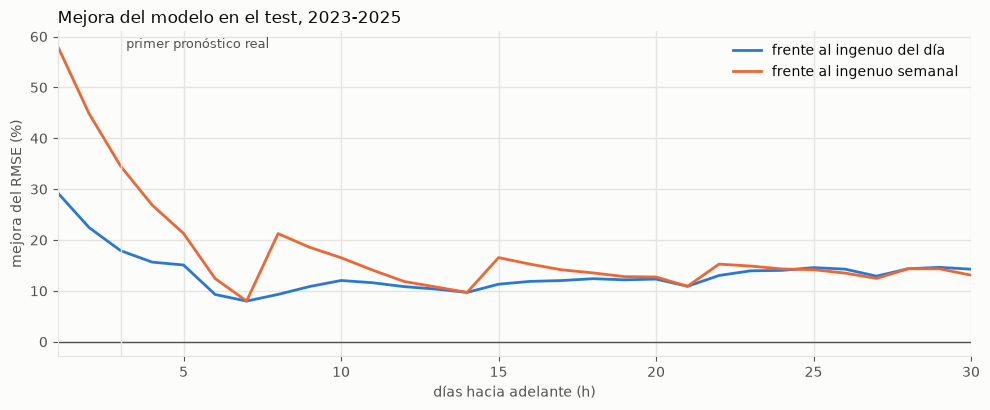

In [10]:
if CORRER_TEST:
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.axhline(0, color=TEXTO_2, lw=1)
    ax.plot(resumen["h"], resumen["mejora_ingenuo"], color=AZUL, label="frente al ingenuo del día")
    ax.plot(resumen["h"], resumen["mejora_semanal"], color=NARANJA, label="frente al ingenuo semanal")
    ax.axvline(3, color=REJILLA, lw=1)
    ax.annotate("primer pronóstico real", (3, ax.get_ylim()[1]), xytext=(4, -12),
                textcoords="offset points", color=TEXTO_2, fontsize=9)
    ax.set(xlabel="días hacia adelante (h)", ylabel="mejora del RMSE (%)", xlim=(1, 30))
    ax.set_title("Mejora del modelo en el test, 2023-2025", loc="left")
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    fig.savefig(SALIDA / "mejora_por_horizonte.png", dpi=150)
    plt.show()

In [11]:
MEJORA_MINIMA = 5.0
NIVEL_DM = 0.05
BLOQUES = {"h = 3": [3], "h = 3 a 7": [3, 4, 5, 6, 7], "h = 8 a 14": list(range(8, 15)),
           "h = 15 a 30": list(range(15, 31))}


def criterio(prueba):
    """El veredicto por bloque, contra el ingenuo de menor RMSE en ese bloque."""
    filas = []
    for nombre, hs in BLOQUES.items():
        d = pd.concat([prueba[h] for h in hs])
        e, e_dia, e_sem = d["y"] - d["y_hat"], d["y"], d["y"] - d["y_semanal"]
        ingenuo, e_ing = min([("del día", e_dia), ("semanal", e_sem)], key=lambda x: rmse(x[1]))
        mejora = 100 * (1 - rmse(e) / rmse(e_ing))
        t, p = diebold_mariano(e.to_numpy(), e_ing.to_numpy(), d["fecha"], max(hs) - 1 + 7)
        filas.append(dict(bloque=nombre, rmse_log=rmse(e), mejor_ingenuo=ingenuo, rmse_ingenuo=rmse(e_ing),
                          mejora=mejora, dm_t=t, dm_p=p, funciona=bool(mejora >= MEJORA_MINIMA and p < NIVEL_DM)))
    return pd.DataFrame(filas)


if CORRER_TEST:
    veredicto = criterio(prueba)
    guardar(veredicto, SALIDA / "prueba_criterio.csv")
    display(veredicto.round(3))

,bloque,rmse_log,mejor_ingenuo,rmse_ingenuo,mejora,dm_t,dm_p,funciona
0,h = 3,0.338,del día,0.411,17.903,-8.652,0.000,True
1,h = 3 a 7,0.413,del día,0.472,12.539,-6.242,0.000,True
2,h = 8 a 14,0.546,del día,0.612,10.679,-2.680,0.007,True
3,h = 15 a 30,0.615,del día,0.708,13.118,-2.415,0.016,True


## Etapa 6b. Test en 2026

Con la configuración congelada y el mismo criterio, desde el 1 de enero hasta el 6 de
octubre de 2026, donde termina el panel. No cambia nada de lo anterior. Son dos planes:

- **Mensual:** el diseño de la etapa 6, reentrenando el 1 de cada mes con todo lo anterior.
- **Fijo:** se entrena una sola vez con 2015-2025 y se pronostica sin volver a entrenar.

Son unos 280 días, frente a los casi 1.100 de la etapa 6, así que Diebold-Mariano tiene
menos potencia. Y 2026 no está intacto: los experimentos de
`legacy/experimentos_xgboost/` ya evaluaron hasta ahí con la selección lineal.

In [12]:
MESES_2026 = ("2026-01-01", "2026-10-01")
PLANES_2026 = {"mensual": meses(*MESES_2026), "fijo": meses(*MESES_2026)[:1]}


def probar_2026(plan):
    ruta = SALIDA / f"prueba2026_{plan}.csv.gz"
    if ruta.exists():
        return dict(tuple(pd.read_csv(ruta, parse_dates=["fecha"]).groupby("h")))
    partes = {}
    for h in HORIZONTES:
        p, ventana = parametros_de(h, config[str(ancla(h))])
        idx, pred = walk_forward(h, p, PLANES_2026[plan], ORIGEN_FINAL, ORIGEN_FINAL, ventana)
        atras = 7 * int(np.ceil(h / 7)) - h
        partes[h] = pd.DataFrame({"fecha": F[idx], "hora": tabla["hora"].to_numpy()[idx], "h": h,
                                  "precio_t": PRECIO[idx], "y": Y[h][idx], "y_hat": pred,
                                  "y_semanal": LP[idx - 24 * atras] - LP[idx]})
    guardar(pd.concat(partes.values(), ignore_index=True), ruta)
    return partes


if CORRER_2026:
    TECHO = ORIGEN_FINAL
    t0 = time.time()
    prueba_2026 = {plan: probar_2026(plan) for plan in PLANES_2026}
    print(f"etapa 6b: {(time.time() - t0) / 60:.0f} min")
    veredicto_2026 = pd.concat([criterio(d).assign(plan=plan) for plan, d in prueba_2026.items()], ignore_index=True)
    resumen_2026 = pd.DataFrame([{"plan": plan, "h": h, **metricas(g, h)}
                                 for plan, d in prueba_2026.items() for h, g in d.items()])
    guardar(veredicto_2026, SALIDA / "prueba2026_criterio.csv")
    guardar(resumen_2026, SALIDA / "prueba2026_resumen.csv")
    display(veredicto_2026.round(3))

etapa 6b: 6 min


,bloque,rmse_log,mejor_ingenuo,rmse_ingenuo,mejora,dm_t,dm_p,funciona,plan
0,h = 3,0.284,del día,0.352,19.455,-4.736,0.000,True,mensual
1,h = 3 a 7,0.361,del día,0.409,11.639,-3.705,0.000,True,mensual
2,h = 8 a 14,0.509,del día,0.543,6.361,-1.667,0.096,False,mensual
3,h = 15 a 30,0.619,semanal,0.577,-7.246,0.913,0.361,False,mensual
4,h = 3,0.285,del día,0.352,19.248,-4.936,0.000,True,fijo
5,h = 3 a 7,0.362,del día,0.409,11.439,-3.785,0.000,True,fijo
6,h = 8 a 14,0.506,del día,0.543,6.819,-1.939,0.053,False,fijo
7,h = 15 a 30,0.620,semanal,0.577,-7.481,0.971,0.331,False,fijo


### Una semana completa, hora por hora

Un solo pronóstico, hecho el 25 de septiembre de 2026, contra el precio real. Son los
días h = 3 a 9: los primeros siete que de verdad se pueden pronosticar, por el atraso
del precio. Es la última semana completa, de lunes a domingo, del panel; se escogió por
esa regla y no por cómo salió. No es una semana típica: salió mejor que la mayoría.

RMSE de esta semana: 0.233; ingenuo del día: 0.250
mediana de 270 cortes: 0.321; con más error que esta semana: 71%
cortes en que el modelo le gana al ingenuo del día: 62%


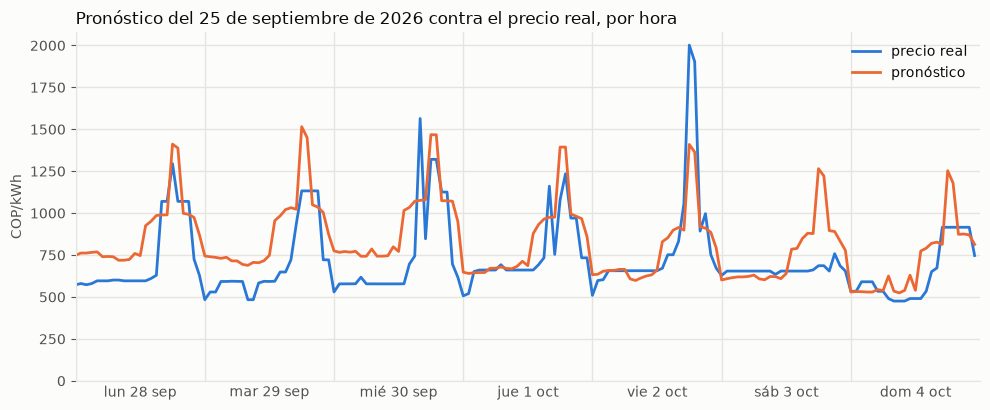

In [13]:
ORIGEN_SEMANA = pd.Timestamp("2026-09-25")
DIAS_SEMANA = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
MESES_AÑO = {9: "sep", 10: "oct"}

if CORRER_2026:
    t = pd.concat([prueba_2026["mensual"][h] for h in range(3, 10)], ignore_index=True)
    t["e2"], t["i2"] = (t["y"] - t["y_hat"]) ** 2, t["y"] ** 2
    cortes = t.groupby("fecha").agg(n=("e2", "size"), modelo=("e2", "mean"), ingenuo=("i2", "mean"))
    cortes = np.sqrt(cortes.loc[cortes["n"] == 168, ["modelo", "ingenuo"]])
    esta = cortes.loc[ORIGEN_SEMANA]
    print(f"RMSE de esta semana: {esta['modelo']:.3f}; ingenuo del día: {esta['ingenuo']:.3f}")
    print(f"mediana de {len(cortes)} cortes: {cortes['modelo'].median():.3f}; "
          f"con más error que esta semana: {100 * (cortes['modelo'] > esta['modelo']).mean():.0f}%")
    print(f"cortes en que el modelo le gana al ingenuo del día: {100 * (cortes['modelo'] < cortes['ingenuo']).mean():.0f}%")

    s = t[t["fecha"] == ORIGEN_SEMANA].copy()
    s["momento"] = s["fecha"] + pd.to_timedelta(s["h"], unit="D") + pd.to_timedelta(s["hora"] - 1, unit="h")
    s = s.sort_values("momento")
    dias = pd.date_range(s["momento"].min().normalize(), periods=7)
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.plot(s["momento"], s["precio_t"] * np.exp(s["y"]), color=AZUL, label="precio real")
    ax.plot(s["momento"], s["precio_t"] * np.exp(s["y_hat"]), color=NARANJA, label="pronóstico")
    ax.set_xticks(dias + pd.Timedelta(hours=12), [f"{DIAS_SEMANA[d.dayofweek]} {d.day} {MESES_AÑO[d.month]}" for d in dias])
    ax.set_xticks(dias, minor=True)
    ax.tick_params(axis="x", which="both", length=0)
    ax.grid(axis="x", which="major", visible=False)
    ax.grid(axis="x", which="minor", color=REJILLA)
    ax.set(ylabel="COP/kWh", ylim=(0, None), xlim=(dias[0], dias[-1] + pd.offsets.Day(1)))
    ax.set_title("Pronóstico del 25 de septiembre de 2026 contra el precio real, por hora", loc="left")
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    fig.savefig(SALIDA / "semana_real_vs_pronostico.png", dpi=150)
    plt.show()

## Etapa 7. Mes final: del 7 de octubre al 5 de noviembre de 2026

Se entrena con todo lo disponible al 6 de octubre y se guarda el pronóstico **antes**
de bajar ningún precio. Por el atraso de publicación del precio, los días reales de
uso empiezan en h = 3. Además, la fila del 6 de octubre no trae `pron_demanda_manana`,
`margen_decl_pron_manana` ni `error_pron_demanda_ultima`, que usan h = 1 y h = 2.

Este mes es una demostración: un solo mes no mide el modelo.

In [14]:
ruta_final = SALIDA / "pronostico_final.csv"
ruta_marca = SALIDA / "pronostico_final_creado.txt"


def pronostico_final():
    fila = np.flatnonzero(F == ORIGEN_FINAL)
    partes = []
    for h in HORIZONTES:
        cfg = config[str(ancla(h))]
        p, ventana = parametros_de(h, cfg)
        cols = columnas(h)
        m = ajustar(para_entrenar(h, ORIGEN_FINAL, ventana), h, cols, p)
        pred = m.predict(M[np.ix_(fila, [POS[c] for c in cols])])
        if cfg["variante"] == "sesgo":
            cortes = meses(str(ORIGEN_FINAL - 100), str(ORIGEN_FINAL))
            idx, previo = walk_forward(h, p, cortes, ORIGEN_FINAL, ORIGEN_FINAL, ventana)
            pred = pred + por_dia(idx, previo, h)["e_dia"].tail(DIAS_SESGO).mean()
        atras = 7 * int(np.ceil(h / 7)) - h
        partes.append(pd.DataFrame({
            "origen": ORIGEN_FINAL, "fecha_objetivo": ORIGEN_FINAL + h, "h": h,
            "hora": tabla["hora"].to_numpy()[fila], "precio_t": PRECIO[fila], "y_hat": pred,
            "precio_pron": PRECIO[fila] * np.exp(pred), "precio_semanal": PRECIO[fila - 24 * atras]}))
    return pd.concat(partes, ignore_index=True)


if CORRER_FINAL:
    TECHO = ORIGEN_FINAL
    if not ruta_final.exists():
        guardar(pronostico_final(), ruta_final)
        ruta_marca.write_text(datetime.now().isoformat(timespec="seconds"), encoding="utf-8")
    final = pd.read_csv(ruta_final, parse_dates=["fecha_objetivo"])
    assert len(final) == 720 and final["precio_pron"].notna().all()
    assert final.groupby("fecha_objetivo").size().eq(24).all()
    print(f"{len(final)} valores, del {final['fecha_objetivo'].min().date()} al "
          f"{final['fecha_objetivo'].max().date()}; creado {ruta_marca.read_text(encoding='utf-8')}")
else:
    print("El mes final no corrió: falta CORRER_FINAL=1")

El mes final no corrió: falta CORRER_FINAL=1


Después del pronóstico se baja solo el precio real, a un archivo aparte. No toca
`datos/` ni los paneles. El precio sale con unos dos días de atraso, así que antes del
7 de noviembre el resultado es parcial; basta correr de nuevo esta celda para completarlo.

In [15]:
def bajar_precio_real():
    from pydataxm.pydataxm import ReadDB
    hasta = min(FIN_MES_FINAL, date.today())
    d = ReadDB().request_data("PrecBolsNaci", "Sistema", date(2026, 10, 7), hasta)
    horas = [f"Values_Hour{h:02d}" for h in range(1, 25)]
    d = d.melt(id_vars="Date", value_vars=horas, var_name="hora", value_name="precio_real")
    d["hora"] = d["hora"].str[-2:].astype(int)
    d["fecha_objetivo"] = pd.to_datetime(d["Date"])
    return d[["fecha_objetivo", "hora", "precio_real"]].dropna().sort_values(["fecha_objetivo", "hora"])


if CORRER_FINAL:
    ruta_real = SALIDA / "precio_real_final.csv"
    guardar(bajar_precio_real(), ruta_real)
    real = pd.read_csv(ruta_real, parse_dates=["fecha_objetivo"])
    mes = final.merge(real, on=["fecha_objetivo", "hora"])
    e = np.log(mes["precio_real"]) - np.log(mes["precio_pron"])
    e_dia = np.log(mes["precio_real"]) - np.log(mes["precio_t"])
    e_sem = np.log(mes["precio_real"]) - np.log(mes["precio_semanal"])
    util = mes[mes["h"] >= 3]
    fila = lambda m, ee: dict(dias=m["fecha_objetivo"].nunique(), rmse_log=rmse(ee), mae_log=float(np.abs(ee).mean()),
                              sesgo=float(ee.mean()),
                              mape=float(100 * np.mean(np.abs(m["precio_real"] - m["precio_pron"]) / m["precio_real"])))
    res = pd.DataFrame({"h = 3 en adelante": fila(util, e[util.index]), "todo el periodo": fila(mes, e)}).T
    res["rmse_ingenuo"] = [rmse(e_dia[util.index]), rmse(e_dia)]
    res["rmse_semanal"] = [rmse(e_sem[util.index]), rmse(e_sem)]
    guardar(res.reset_index(names="alcance"), SALIDA / "mes_final_resumen.csv")
    print(f"cubre {mes['fecha_objetivo'].nunique()} de 30 días")
    display(res.round(3))

    dia = mes.groupby("fecha_objetivo")[["precio_real", "precio_pron", "precio_semanal"]].mean()
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.plot(dia.index, dia["precio_real"], color=AZUL, label="precio real")
    ax.plot(dia.index, dia["precio_pron"], color=NARANJA, label="pronóstico del 6 de octubre")
    ax.set(ylabel="promedio del día (COP/kWh)")
    ax.set_title(f"Mes final: pronóstico frente al precio real ({len(dia)} días)", loc="left")
    ax.legend(frameon=False)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(SALIDA / "mes_final.png", dpi=150)
    plt.show()